Following the Petkov paper:
https://cit.iict.bas.bg/CIT_2010/v10-2/31-40.pdf

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve
from scipy._lib._util import check_random_state
from scipy.optimize import nnls


In [2]:
# Section C of https://doi.org/10.1109/IEEESTD.1998.86153
# ADIS16350 datasheet https://www.analog.com/media/en/technical-documentation/data-sheets/ADIS16350_16355.pdf

d2r = np.deg2rad(1.0)
r2d = np.rad2deg(1.0)

# From the datasheet
f0 = 350         # cut-off freq           (Hz)              # Taken straight from the datasheet 3dB BW

# From Their Allan Variance fit
N = d2r*5.75e-2  # angle RW coeff         (deg/sqrt(s))     # 0.07 deg/rt(s) on datasheet 4.2 deg/sqrt(hr) "angular random walk"
B = d2r*1.55e-2  # bias instability coeff (deg/s)           # 0.015 deg/s on datasheet "in run bias stability"
K = d2r*9e-4     # Rate RW coeff          (deg/sqrt(s))     # 0.05 deg/rt(s) "rate noise density RMS"

# PSD Contributions from the IEEE standard linked above
S_arw = lambda f: np.ones_like(f)*N**2
S_bias = lambda f: f**(-1)*B**2/(2*np.pi)* (f < f0)
S_rrw = lambda f: f**(-2)*(K / 2*np.pi)**2

In [9]:
1/ (2*np.pi*120)

0.0013262911924324613

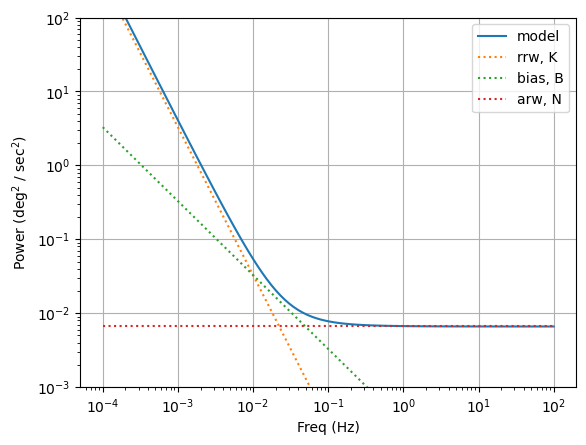

In [6]:
fs = 10**np.linspace(-4,2, 100)
SSB = 2 * (S_arw(fs) + S_bias(fs) + S_rrw(fs))

rsq2dsq = r2d**2 ## convert plot to degrees squared per second square

plt.figure()
plt.loglog(fs, rsq2dsq*SSB)
plt.grid()
plt.xlabel("Freq (Hz)")
plt.ylabel("Power (deg$^{2}$ / sec$^{2}$)")

# plot guides
plt.loglog(fs, rsq2dsq*10**np.log10(fs**-2) / 1e9, ':')
plt.loglog(fs, rsq2dsq*(fs**-1)/1e7, ':')
plt.loglog(fs, rsq2dsq*2*S_arw(fs), ':')
plt.ylim(1e-3,1e2)
plt.legend(["model", "rrw, K", "bias, B", "arw, N"])

In [7]:
# Total gyro noise, directly measured
sigma_gyro_noise = 0.581614 #deg/s

## Bias Instability: Equations 3 and 4
Bias instability modelled by

$T\dot{x}(t) + x(t) = v(t)$,

- $x(t)$ is a Gauss-Markov process, representing the bias error (what they're trying to model). This is the time-varying part of the bias, not the constant bias offset (estimated and subtracted by calibration).
- $v(t)$ is input white noise. Zero mean, Gaussian.
- $T$ scales how quickly the bias changes.
- If input noise $v(t)$ becomes zero, $x(t)$ slowly decays to zero as well. $\dot{x} =  - x/T$ is exponential decay.
- Gaussian inputs, with Markovian future propagation. The future depends on the current state, not entire history.
- $x(t)$ will have zero mean if $v(t)$ has zero mean.

$T$ is pulled from Figure 3 (Allan Var plot). There may be ways of fitting this properly. It's not clear that this is a robust approach.

For long $T$, the knee of The Allan Variance (transition to from $K$ to $B$) is smoother. For short $T$, the curve is sharper. 

To understand this in frequency space, for first-order Gauss-Markov processes, the PSD shape is

$S(f) \propto \frac{1}{1 + (2\pi f T)^{2}}$

So, $T$ determines the corner frequency of the bias instability PSDcomponent

$f_c = 1 / 2 \pi T$